In [2]:
!pip install -q stable-baselines3[extra] sb3-contrib yfinance gymnasium hmmlearn scikit-learn transformers accelerate sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.0/93.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.5/187.5 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 89.9 MB/s eta 0:00:00:00:010:01


2026-04-25 00:18:07.945868: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777076288.170559      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777076288.234935      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777076288.792682      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777076288.792732      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777076288.792736      55 computation_placer.cc:177] computation placer alr

[device] GPU · Tesla T4  15.6 GB VRAM
[data] downloading 30 tickers 2012-01-01→2026-04-25 …
[data] 30 tickers · 105,347 rows  (2012-02-09 → 2026-04-24)
[macro] downloading ^VIX, ^TNX …
[macro] VIX 3598d  |  TNX 3597d
[regime] fitting HMM …
[regime] counts: {'bull_low_vol': np.int64(1115), 'bull_high_vol': np.int64(509), 'bear_high_vol': np.int64(115)}


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[sentiment] FinBERT loaded ✓
[sentiment] fetching news for 30 tickers …
[sentiment] 3572 days total  FinBERT=0  VIX-proxy=3572
[arrays] computing vol-targeted position limits …
[arrays] ready  T=3572  N=30  obs_dim=246
[split] train=2992d  val=252d  trade=328d
[agents] missing: ['TQC.zip', 'CrossQ.zip', 'TD3.zip', 'RPPO.zip']
[agents] training TQC · CrossQ · TD3 · RPPO …
  TQC (200,000 steps) …
    [TQC]   2,000/200,000 (  1.0%)  Δ=   7s  total=    7s
    [TQC]   4,000/200,000 (  2.0%)  Δ=   8s  total=   15s
    [TQC]   6,000/200,000 (  3.0%)  Δ=   8s  total=   23s
    [TQC]   8,000/200,000 (  4.0%)  Δ=   8s  total=   31s
    [TQC]  10,000/200,000 (  5.0%)  Δ=   8s  total=   39s
    [TQC]  12,000/200,000 (  6.0%)  Δ=   8s  total=   47s
    [TQC]  14,000/200,000 (  7.0%)  Δ=   8s  total=   55s
    [TQC]  16,000/200,000 (  8.0%)  Δ=   8s  total=   63s
    [TQC]  18,000/200,000 (  9.0%)  Δ=   8s  total=   71s
    [TQC]  20,000/200,000 ( 10.0%)  Δ=   8s  total=   80s
    [TQC]  22,000/200,

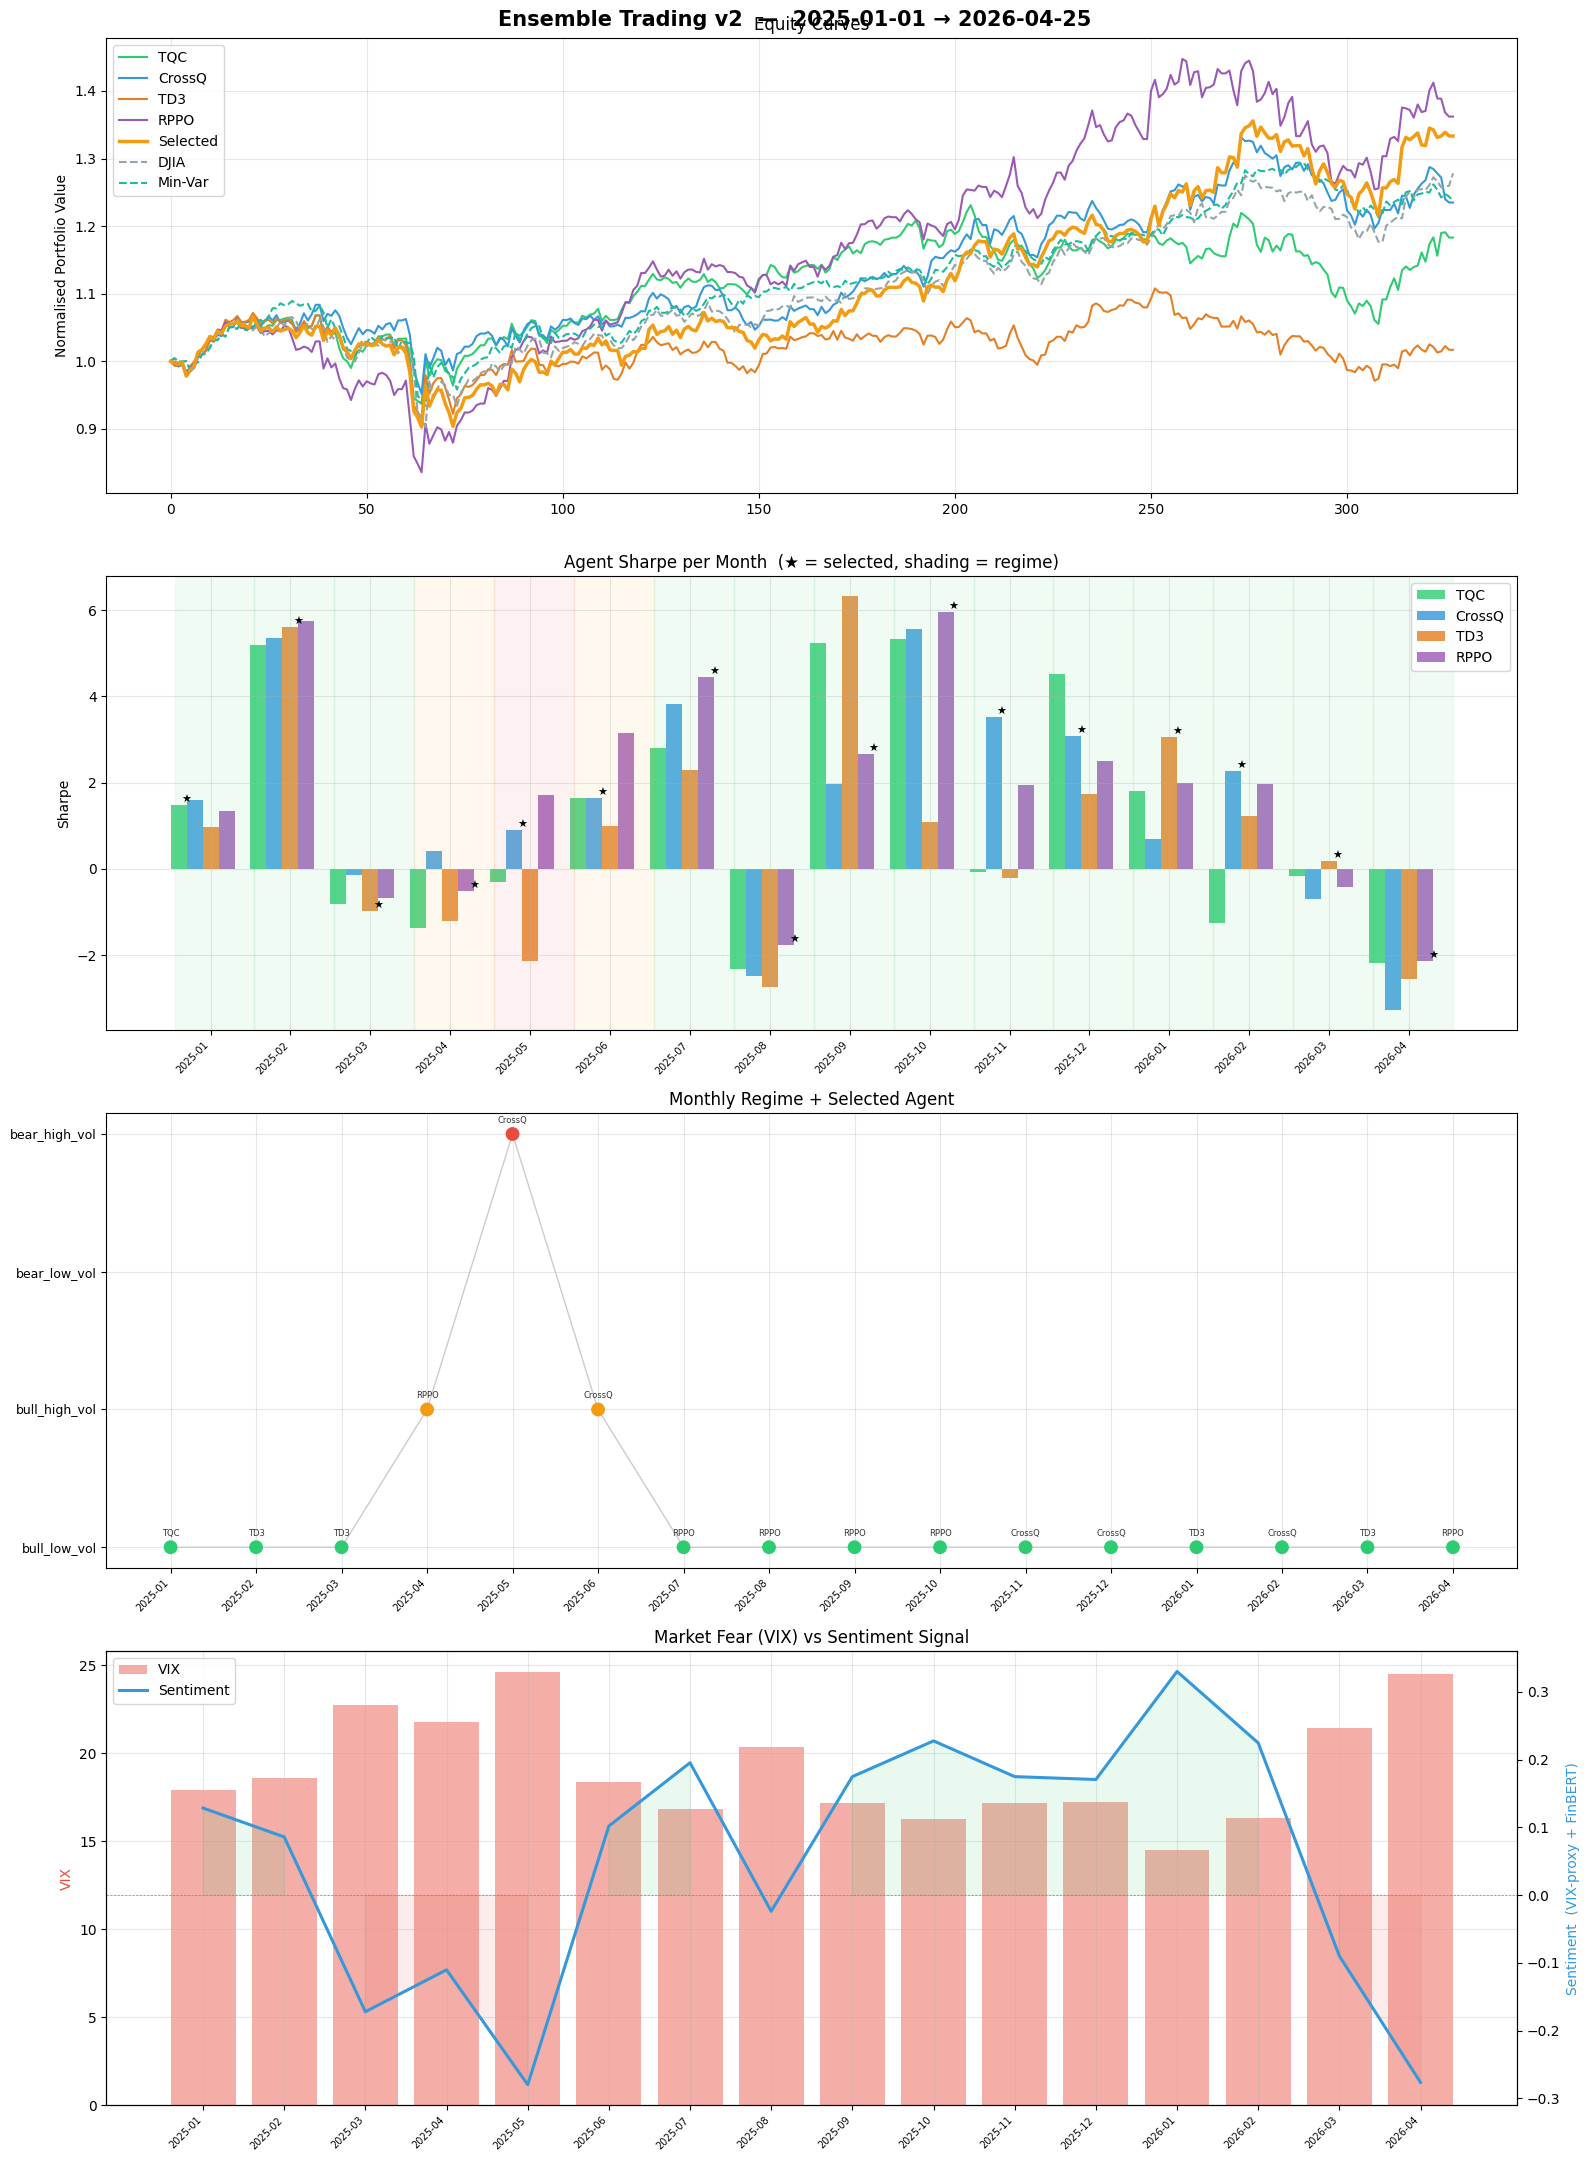


[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …

[signal] interrupted — saving agents …
[signal] interrupted — saving agents …


[signal] interrupted — saving agents …
[signal] interrupted — saving agents …





[signal] interrupted — saving agents …

[signal] interrupted — saving agents …


[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …


[signal] interrupted — saving agents …


[signal] interrupted — saving agents …
[signal] interrupted — saving agents …
[signal] interrupted — saving agents …

[signal]

In [3]:
"""
Ensemble Trading v2 — Gating Network + Sentiment + Risk Management
===================================================================

UPGRADES over v1
────────────────
① FinBERT sentiment pipeline
    • yfinance news → ProsusAI/finbert → daily scores, disk-cached
    • VIX-proxy fallback for every date with no news coverage
      (VIX≈10 → +0.8, VIX≈20 → 0.0, VIX≈40 → -0.8)
② Macro observation features
    • ^VIX (normalised), daily VIX change, 10-year yield (^TNX)
    • Sentiment score from ①
    • obs_dim = 1 + 8·N + 5  (was 1 + 8·N + 1)
③ Sortino-based reward
    • Only penalises downside volatility (negative returns)
    • Aligns optimisation with what you care about
④ Volatility-targeted per-stock position sizing
    • HMAX replaced by 20-day-vol-scaled limit per stock per day
    • High-vol stocks get smaller positions automatically
⑤ Portfolio drawdown brake
    • Tracks monthly equity peak
    • If portfolio drops >5 % from peak → linearly scales actions to 0
    • Applied multiplicatively on top of turbulence scaling
⑥ Expanded gating network (dim 11)
    • regime_one_hot(4) + sharpe_norm(4) + VIX(1) + sentiment(1) + yield(1)

AGENTS
──────
TQC           Distributional critics, best in bear_high_vol
CrossQ        Fastest convergence, best in bear_low_vol
TD3           Committed directional policy, best in bull_low_vol
RecurrentPPO  LSTM, captures multi-day momentum, best in bull_high_vol

TIMELINE
────────
Train 2012-2023 · Validate 2024 · Trade 2025 → today
Monthly cadence: detect regime → compute sharpes → gate → fine-tune → run

KAGGLE INSTALL (cell 1)
───────────────────────
!pip install -q stable-baselines3[extra] sb3-contrib yfinance gymnasium \\
    hmmlearn scikit-learn transformers accelerate sentencepiece
"""

import warnings; warnings.filterwarnings("ignore")
import os, json, logging, time, signal, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import gymnasium as gym
from gymnasium import spaces
from pathlib import Path
from datetime import date

from stable_baselines3 import TD3
from stable_baselines3.common.noise import NormalActionNoise
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.vec_env import SubprocVecEnv, DummyVecEnv
from sb3_contrib import TQC, CrossQ, RecurrentPPO

from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.optim as optim

logging.basicConfig(level=logging.WARNING)

if torch.cuda.is_available():
    DEVICE = "cuda"
    torch.backends.cudnn.benchmark        = True
    torch.backends.cuda.matmul.allow_tf32 = True
    print(f"[device] GPU · {torch.cuda.get_device_name(0)}  "
          f"{torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB VRAM")
else:
    DEVICE = "cpu"
    print("[device] CPU")


# ══════════════════════════════════════════════════════════════
# PROGRESS CALLBACK
# ══════════════════════════════════════════════════════════════
class ProgressCallback(BaseCallback):
    LOG_INTERVAL = 2_000

    def __init__(self, agent_name: str, total_timesteps: int):
        super().__init__()
        self.agent_name      = agent_name
        self.total_timesteps = total_timesteps
        self._t0 = self._interval_t0 = None

    def _on_training_start(self):
        self._t0 = self._interval_t0 = time.time()

    def _on_step(self) -> bool:
        n = self.num_timesteps
        if n % self.LOG_INTERVAL == 0:
            pct     = n / self.total_timesteps * 100
            elapsed = time.time() - self._t0
            ivl     = time.time() - self._interval_t0
            print(f"    [{self.agent_name}] {n:>7,}/{self.total_timesteps:,} "
                  f"({pct:5.1f}%)  Δ={ivl:4.0f}s  total={elapsed:5.0f}s", flush=True)
            self._interval_t0 = time.time()
        return True


# ══════════════════════════════════════════════════════════════
# CONFIG
# ══════════════════════════════════════════════════════════════
# ── Output / checkpoint paths ────────────────────────────────
#    Change BASE_DIR to Path(".") when running locally
BASE_DIR             = Path("/kaggle/working")
AGENTS_DIR           = BASE_DIR / "agents"
GATING_DATA_FILE     = BASE_DIR / "gating_dataset.json"
GATING_MODEL_FILE    = BASE_DIR / "gating_net.pt"
SENTIMENT_CACHE_FILE = BASE_DIR / "sentiment_cache.parquet"

TICKERS = [
    "AAPL","MSFT","JPM","JNJ","V","PG","UNH","HD","MA","INTC",
    "VZ","MRK","DIS","BA","MMM","IBM","AXP","GS","CAT","MCD",
    "NKE","WMT","TRV","CVX","RTX","DOW","AMGN","HON","CRM","KO",
]

TRAIN_START = "2012-01-01"
TRAIN_END   = "2023-12-31"
VAL_START   = "2024-01-01"
VAL_END     = "2024-12-31"
TRADE_START = "2025-01-01"
TRADE_END   = date.today().strftime("%Y-%m-%d")

INITIAL_CAPITAL  = 1_000_000
TRANSACTION_COST = 0.001
HMAX             = 100          # normalisation constant (obs only)

# ── Training ─────────────────────────────────────────────────
TRAIN_TIMESTEPS    = 200_000
RPPO_TIMESTEPS     = 120_000
FINETUNE_TIMESTEPS =  20_000

# ── SB3 hyper-parameters ─────────────────────────────────────
BATCH_SIZE          = 256
BUFFER_SIZE         = 100_000
GRADIENT_STEPS      = 1
GRADIENT_STEPS_FINE = 2
N_ENVS              = 4
LEARNING_STARTS     = 500
NET_ARCH            = [256, 256]
FINETUNE_LOOKBACK   = 252
SHARPE_EVAL_DAYS    = 21

# ── Reward ───────────────────────────────────────────────────
REWARD_VOL_WINDOW   = 20
OVERTRADING_PENALTY = 0.001

# ── Risk management ──────────────────────────────────────────
DD_THRESHOLD     = 0.05    # 5 % monthly-peak drop → brake starts
TARGET_STOCK_VOL = 0.02    # 2 % target daily vol per position
MIN_VOL_HMAX     = 10
MAX_VOL_HMAX     = 500

# ── Turbulence scaling ───────────────────────────────────────
TURB_MIDPOINT  = 150
TURB_STEEPNESS = 50
TURB_FLOOR     = 0.05

# ── Regime detection ─────────────────────────────────────────
N_REGIMES     = 4
REGIME_WINDOW = 20
REGIME_NAMES  = ["bull_low_vol", "bull_high_vol", "bear_low_vol", "bear_high_vol"]

# ── Gating network ───────────────────────────────────────────
AGENT_NAMES      = ["TQC", "CrossQ", "TD3", "RPPO"]
N_AGENTS         = len(AGENT_NAMES)
# regime(4) + sharpe_norm(4) + VIX_norm(1) + sentiment(1) + yield_norm(1) = 11
GATING_INPUT_DIM = N_REGIMES + N_AGENTS + 3
MIN_GATING_SAMPLES = 4
GATING_LR          = 1e-3
GATING_EPOCHS      = 200


# ══════════════════════════════════════════════════════════════
# SENTIMENT PIPELINE
# ══════════════════════════════════════════════════════════════
_FINBERT_PIPE = None   # lazy-loaded singleton


def _norm_ts(ts) -> pd.Timestamp:
    """Normalise any timestamp to a tz-naive date."""
    t = pd.Timestamp(ts)
    if t.tzinfo is not None:
        t = t.tz_localize(None)
    return t.normalize()


def get_finbert():
    """Lazy-load FinBERT; returns None if transformers is unavailable."""
    global _FINBERT_PIPE
    if _FINBERT_PIPE is not None:
        return None if _FINBERT_PIPE == "unavailable" else _FINBERT_PIPE
    try:
        from transformers import pipeline as hf_pipeline
        dev = 0 if torch.cuda.is_available() else -1
        _FINBERT_PIPE = hf_pipeline(
            "text-classification",
            model="ProsusAI/finbert",
            device=dev,
            truncation=True,
            max_length=512,
            batch_size=32,
        )
        print("[sentiment] FinBERT loaded ✓", flush=True)
    except Exception as e:
        print(f"[sentiment] FinBERT unavailable ({e}); using VIX proxy only")
        _FINBERT_PIPE = "unavailable"
    return None if _FINBERT_PIPE == "unavailable" else _FINBERT_PIPE


def vix_to_sentiment(vix_val: float) -> float:
    """
    Sigmoid mapping  VIX → [-1, +1].
    VIX ≈ 10 → +0.80 (calm = bullish)
    VIX ≈ 20 → +0.00 (neutral)
    VIX ≈ 40 → -0.80 (fear = bearish)
    """
    return float(np.clip(-(2.0 / (1.0 + np.exp(-(vix_val - 20.0) / 8.0)) - 1.0), -1.0, 1.0))


def _fetch_ticker_news(ticker_str: str):
    """Return list of (headline_str, unix_timestamp) for a ticker."""
    try:
        items = []
        for n in (yf.Ticker(ticker_str).news or []):
            title = n.get("title", n.get("headline", ""))
            ts    = n.get("providerPublishTime", n.get("published", 0))
            if isinstance(ts, str):
                try:    ts = int(pd.Timestamp(ts).timestamp())
                except: ts = 0
            if title and ts:
                items.append((str(title), int(ts)))
        return items
    except Exception:
        return []


def _score_batch(pipe, texts: list) -> list:
    """Run FinBERT on a list of texts; return float scores in [-1, +1]."""
    results = pipe(texts, truncation=True, max_length=512)
    out = []
    for r in results:
        label, conf = r["label"], r["score"]
        out.append(conf if label == "positive" else (-conf if label == "negative" else 0.0))
    return out


def build_sentiment_series(tickers, all_dates, vix_series) -> np.ndarray:
    """
    Return float32 array of shape (T,) with daily sentiment ∈ [-1, +1].

    Strategy
    ────────
    1. Load existing parquet cache (persists across Kaggle sessions).
    2. Fetch yfinance news for all tickers → score with FinBERT → cache.
    3. For every date without a FinBERT score, use VIX-proxy fallback.
    """
    BASE_DIR.mkdir(parents=True, exist_ok=True)

    # ── 1. Load cache ────────────────────────────────────────
    if SENTIMENT_CACHE_FILE.exists():
        cached_df = pd.read_parquet(SENTIMENT_CACHE_FILE)
        cached_df["date"] = pd.to_datetime(cached_df["date"]).apply(_norm_ts)
        print(f"[sentiment] loaded {len(cached_df)} cached dates", flush=True)
    else:
        cached_df = pd.DataFrame(columns=["date", "sentiment"])

    cached_dates = set(cached_df["date"].tolist())

    # ── 2. Fetch + score recent headlines ────────────────────
    pipe = get_finbert()
    if pipe is not None:
        all_items = []   # (norm_date, headline)
        print(f"[sentiment] fetching news for {len(tickers)} tickers …", flush=True)
        for tk in tickers:
            for title, ts in _fetch_ticker_news(tk):
                d = _norm_ts(pd.Timestamp(ts, unit="s"))
                if d not in cached_dates:
                    all_items.append((d, title))

        if all_items:
            dates_list = [i[0] for i in all_items]
            texts      = [i[1] for i in all_items]
            print(f"[sentiment] scoring {len(texts)} headlines …", flush=True)
            try:
                scores = _score_batch(pipe, texts)
                new_df = pd.DataFrame({"date": dates_list, "sentiment": scores})
                new_df = new_df.groupby("date")["sentiment"].mean().reset_index()
                cached_df = (pd.concat([cached_df, new_df], ignore_index=True)
                               .drop_duplicates("date")
                               .sort_values("date")
                               .reset_index(drop=True))
                cached_df.to_parquet(SENTIMENT_CACHE_FILE)
                print(f"[sentiment] cache updated → {len(cached_df)} scored dates")
            except Exception as e:
                print(f"[sentiment] FinBERT scoring error: {e}")

    # Build fast lookup
    date_to_score = dict(zip(cached_df["date"], cached_df["sentiment"])) if not cached_df.empty else {}

    # Build VIX lookup for fallback
    vix_dict = {}
    if isinstance(vix_series, pd.Series):
        for k, v in vix_series.items():
            if not (isinstance(v, float) and np.isnan(v)):
                vix_dict[_norm_ts(k)] = float(v)

    # ── 3. Assemble full array ────────────────────────────────
    result = []
    n_finbert = 0
    for d in all_dates:
        dt = _norm_ts(d)
        if dt in date_to_score:
            result.append(float(date_to_score[dt]))
            n_finbert += 1
        else:
            vix_val = vix_dict.get(dt, 20.0)
            result.append(vix_to_sentiment(vix_val))

    print(f"[sentiment] {len(result)} days total  "
          f"FinBERT={n_finbert}  VIX-proxy={len(result)-n_finbert}", flush=True)
    return np.array(result, dtype=np.float32)


# ══════════════════════════════════════════════════════════════
# DATA DOWNLOAD
# ══════════════════════════════════════════════════════════════
def download_data(tickers, start, end):
    print(f"[data] downloading {len(tickers)} tickers {start}→{end} …", flush=True)
    raw    = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)
    close  = raw["Close"].ffill().dropna(axis=1, how="all")
    high   = raw["High"].ffill()
    low    = raw["Low"].ffill()
    volume = raw["Volume"].ffill().fillna(0)
    avail  = close.columns.tolist()
    close, high, low, volume = close[avail], high[avail], low[avail], volume[avail]

    frames = []
    for t in avail:
        c, h, l, v = close[t], high[t], low[t], volume[t]
        macd = c.ewm(span=12).mean() - c.ewm(span=26).mean()
        d    = c.diff()
        rsi  = 100 - 100 / (1 + d.clip(lower=0).rolling(14).mean() /
                                (-d.clip(upper=0).rolling(14).mean() + 1e-9))
        tp   = (h + l + c) / 3
        cci  = (tp - tp.rolling(20).mean()) / (0.015 * tp.rolling(20).std() + 1e-9)
        tr   = pd.concat([h-l, (h-c.shift()).abs(), (l-c.shift()).abs()], axis=1).max(axis=1)
        adx  = (tr.rolling(14).mean() / (c + 1e-9) * 100).rolling(14).mean()
        bb_pos    = (c - c.rolling(20).mean()) / (2 * c.rolling(20).std() + 1e-9)
        vol_ratio = v / (v.rolling(20).mean() + 1e-9)
        frames.append(pd.DataFrame({
            "date": c.index, "ticker": t,
            "close":     c.values,         "macd":      macd.values,
            "rsi":       rsi.values,        "cci":       cci.values,
            "adx":       adx.values,        "bb_pos":    bb_pos.values,
            "vol_ratio": vol_ratio.values,
        }))

    data = pd.concat(frames, ignore_index=True).dropna()
    print(f"[data] {data['ticker'].nunique()} tickers · {len(data):,} rows  "
          f"({data['date'].min().date()} → {data['date'].max().date()})")
    return data


def download_macro(start, end):
    """Download VIX and 10-year Treasury yield from yfinance."""
    print("[macro] downloading ^VIX, ^TNX …", flush=True)

    def _get_close(sym, default):
        try:
            raw = yf.download(sym, start=start, end=end, auto_adjust=True, progress=False)
            if raw.empty:
                return pd.Series(dtype=float)
            if isinstance(raw.columns, pd.MultiIndex):
                raw.columns = raw.columns.droplevel(1)
            s = raw["Close"].ffill().bfill()
            s.index = pd.to_datetime(s.index)
            return s
        except Exception as e:
            print(f"[macro] {sym} download failed: {e}")
            return pd.Series(dtype=float)

    vix_s = _get_close("^VIX", 20.0)
    tny_s = _get_close("^TNX",  3.0)
    print(f"[macro] VIX {len(vix_s)}d  |  TNX {len(tny_s)}d")
    return vix_s, tny_s


# ══════════════════════════════════════════════════════════════
# TURBULENCE
# ══════════════════════════════════════════════════════════════
def compute_turbulence(price_df):
    returns = price_df.pct_change().dropna()
    mu      = returns.mean().values
    cov_inv = np.linalg.pinv(returns.cov().values)
    R       = returns.values - mu
    t       = np.einsum("ti,ij,tj->t", R, cov_inv, R)
    s       = pd.Series(t, index=returns.index)
    mn, mx  = s.min(), s.max()
    return (s - mn) / (mx - mn) * 400 if mx > mn else s


def compute_turbulence_forecast(turb):
    vals  = turb.values.astype(np.float64)
    mu    = vals.mean()
    y, x  = vals[1:] - mu, vals[:-1] - mu
    phi   = float(np.dot(x, y) / (np.dot(x, x) + 1e-9))
    phi   = np.clip(phi, -0.99, 0.99)
    fcast = np.clip(mu + phi * (vals - mu), 0, 400)
    return pd.Series(fcast, index=turb.index)


def turb_scale(turb_value: float) -> float:
    raw = 1.0 / (1.0 + np.exp((turb_value - TURB_MIDPOINT) / TURB_STEEPNESS))
    return float(max(TURB_FLOOR, raw))


# ══════════════════════════════════════════════════════════════
# REGIME DETECTION
# ══════════════════════════════════════════════════════════════
def fit_regime_hmm(price_df):
    try:
        port_ret = price_df.pct_change().dropna().mean(axis=1)
        roll_mu  = port_ret.rolling(REGIME_WINDOW).mean().dropna()
        roll_vol = port_ret.rolling(REGIME_WINDOW).std().dropna()
        idx      = roll_mu.index.intersection(roll_vol.index)
        X        = np.column_stack([roll_mu.loc[idx].values, roll_vol.loc[idx].values])
        scaler   = StandardScaler()
        X_sc     = scaler.fit_transform(X)
        model    = GaussianHMM(n_components=N_REGIMES, covariance_type="diag",
                               n_iter=500, random_state=42, min_covar=1e-3)
        model.fit(X_sc)
        return (model, idx, scaler)
    except Exception as e:
        print(f"[regime] HMM fitting failed: {e}")
        return None


def label_regimes(model_tuple, price_df):
    if model_tuple is None:
        return pd.Series(dtype=str)
    hmm, idx, scaler = model_tuple
    port_ret = price_df.pct_change().dropna().mean(axis=1)
    roll_mu  = port_ret.rolling(REGIME_WINDOW).mean().dropna()
    roll_vol = port_ret.rolling(REGIME_WINDOW).std().dropna()
    common   = roll_mu.index.intersection(roll_vol.index)
    X        = np.column_stack([roll_mu.loc[common].values, roll_vol.loc[common].values])
    X_sc     = scaler.transform(X)
    raw      = hmm.predict(X_sc)
    state_mu  = np.array([X[raw==s, 0].mean() if (raw==s).any() else 0
                           for s in range(N_REGIMES)])
    state_vol = np.array([X[raw==s, 1].mean() if (raw==s).any() else 0
                           for s in range(N_REGIMES)])
    med_vol   = np.median(state_vol)
    s2r = {}
    for s in range(N_REGIMES):
        bull = state_mu[s] >= 0
        hv   = state_vol[s] >= med_vol
        s2r[s] = ("bull_high_vol" if bull and hv else
                  "bull_low_vol"  if bull else
                  "bear_high_vol" if hv else
                  "bear_low_vol")
    return pd.Series([s2r[s] for s in raw], index=common)


def get_current_regime(regime_series, date_idx):
    if regime_series.empty:
        return "unknown"
    available = regime_series.index[regime_series.index <= date_idx]
    if len(available) == 0:
        return "unknown"
    val = regime_series.loc[available[-1]]
    return str(val if not isinstance(val, pd.Series) else val.iloc[-1])


# ══════════════════════════════════════════════════════════════
# GATING NETWORK  (11-dim input)
# ══════════════════════════════════════════════════════════════
class GatingNet(nn.Module):
    """
    Input  (11): regime_one_hot(4) + norm_sharpe(4) + VIX_norm(1) + sentiment(1) + yield_norm(1)
    Output     : logits over N_AGENTS → argmax → selected agent index
    """
    def __init__(self, input_dim=GATING_INPUT_DIM, hidden=32, n_agents=N_AGENTS):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden, 16),
            nn.ReLU(),
            nn.Linear(16, n_agents),
        )

    def forward(self, x):
        return self.net(x)

    def predict(self, regime, sharpes,
                vix_val=20.0, sentiment_val=0.0, yield_val=3.0) -> str:
        feat = _gating_features(regime, sharpes, vix_val, sentiment_val, yield_val)
        x    = torch.tensor(feat, dtype=torch.float32).unsqueeze(0)
        self.eval()
        with torch.no_grad():
            idx = int(self.forward(x).argmax(dim=1).item())
        return AGENT_NAMES[idx]


def _gating_features(regime, sharpes,
                     vix_val=20.0, sentiment_val=0.0, yield_val=3.0) -> np.ndarray:
    one_hot = np.zeros(N_REGIMES, dtype=np.float32)
    if regime in REGIME_NAMES:
        one_hot[REGIME_NAMES.index(regime)] = 1.0
    sv = np.array([sharpes.get(n, 0.0) for n in AGENT_NAMES], dtype=np.float32)
    s_min, s_max = sv.min(), sv.max()
    if s_max > s_min:
        sv = (sv - s_min) / (s_max - s_min) * 2.0 - 1.0
    macro = np.array([
        float(vix_val)       / 100.0,
        float(sentiment_val),           # already in [-1, +1]
        float(yield_val)     / 10.0,
    ], dtype=np.float32)
    return np.concatenate([one_hot, sv, macro])   # len = 11


# ── Gating dataset I/O ───────────────────────────────────────
def load_gating_dataset():
    if GATING_DATA_FILE.exists():
        with open(GATING_DATA_FILE) as f:
            return json.load(f)
    return []


def save_gating_dataset(dataset):
    with open(GATING_DATA_FILE, "w") as f:
        json.dump(dataset, f, indent=2)


def append_gating_sample(dataset, regime, sharpes, winner,
                          vix_val=20.0, sentiment_val=0.0, yield_val=3.0):
    label = AGENT_NAMES.index(winner) if winner in AGENT_NAMES else 0
    dataset.append({
        "regime":    regime,
        "sharpes":   sharpes,
        "label":     label,
        "vix":       float(vix_val),
        "sentiment": float(sentiment_val),
        "yield_val": float(yield_val),
    })
    return dataset


# ── Cold-start prior (used before MIN_GATING_SAMPLES months) ─
REGIME_PRIOR = {
    "bull_low_vol":  ["TD3",   "TQC",   "RPPO",  "CrossQ"],
    "bull_high_vol": ["RPPO",  "TQC",   "CrossQ","TD3"   ],
    "bear_low_vol":  ["CrossQ","RPPO",  "TQC",   "TD3"   ],
    "bear_high_vol": ["TQC",   "CrossQ","RPPO",  "TD3"   ],
    "unknown":       ["TQC",   "CrossQ","RPPO",  "TD3"   ],
}


def coldstart_select(regime, sharpes) -> str:
    prior_rank   = REGIME_PRIOR.get(regime, REGIME_PRIOR["unknown"])
    n            = len(AGENT_NAMES)
    prior_score  = {a: (n - prior_rank.index(a)) / n for a in AGENT_NAMES}
    sv           = np.array([sharpes.get(a, 0.0) for a in AGENT_NAMES])
    s_min, s_max = sv.min(), sv.max()
    sh_norm  = (sv - s_min) / (s_max - s_min) if s_max > s_min else np.ones(n) / n
    sh_score = {a: float(sh_norm[i]) for i, a in enumerate(AGENT_NAMES)}
    combined = {a: 0.6 * prior_score[a] + 0.4 * sh_score[a] for a in AGENT_NAMES}
    return max(combined, key=combined.get)


def train_gating_net(dataset) -> GatingNet:
    net = GatingNet()
    if len(dataset) < 2:
        return net
    X = np.array([
        _gating_features(d["regime"], d["sharpes"],
                         d.get("vix", 20.0),
                         d.get("sentiment", 0.0),
                         d.get("yield_val", 3.0))
        for d in dataset], dtype=np.float32)
    y    = np.array([d["label"] for d in dataset], dtype=np.int64)
    X_t  = torch.tensor(X)
    y_t  = torch.tensor(y)
    opt  = optim.Adam(net.parameters(), lr=GATING_LR)
    crit = nn.CrossEntropyLoss()
    net.train()
    for _ in range(GATING_EPOCHS):
        opt.zero_grad()
        loss = crit(net(X_t), y_t)
        loss.backward()
        opt.step()
    print(f"[gating] trained {len(dataset)} samples  loss={loss.item():.4f}", flush=True)
    return net


def save_gating_net(net):
    torch.save(net.state_dict(), GATING_MODEL_FILE)


def load_gating_net():
    if not GATING_MODEL_FILE.exists():
        return None
    net = GatingNet()
    net.load_state_dict(torch.load(GATING_MODEL_FILE, map_location="cpu"))
    return net


def select_agent(regime, sharpes, gating_net, dataset,
                 vix_val=20.0, sentiment_val=0.0, yield_val=3.0) -> str:
    if gating_net is not None and len(dataset) >= MIN_GATING_SAMPLES:
        return gating_net.predict(regime, sharpes, vix_val, sentiment_val, yield_val)
    return coldstart_select(regime, sharpes)


# ══════════════════════════════════════════════════════════════
# MARKET ARRAYS
# ══════════════════════════════════════════════════════════════
class MarketArrays:
    def __init__(self, data, turbulence, turb_forecast, tickers,
                 vix_series, tny_series, sentiment_arr: np.ndarray):
        dates        = sorted(data["date"].unique())
        self.dates   = dates
        self.T       = len(dates)
        self.tickers = tickers
        self.N       = len(tickers)

        # ── Pivot price / indicator tables ────────────────────
        def _pivot(col):
            return (data.pivot(index="date", columns="ticker", values=col)
                        .reindex(index=dates, columns=tickers)
                        .ffill().fillna(0.0).values.astype(np.float32))

        self.prices    = _pivot("close")
        self.macd      = _pivot("macd")
        self.rsi       = _pivot("rsi")
        self.cci       = _pivot("cci")
        self.adx       = _pivot("adx")
        self.bb_pos    = _pivot("bb_pos")
        self.vol_ratio = _pivot("vol_ratio")

        # ── Macro scalar arrays ───────────────────────────────
        def _macro_at(series, default: float) -> np.ndarray:
            if not isinstance(series, pd.Series) or series.empty:
                return np.full(len(dates), float(default), dtype=np.float32)
            lkup = {_norm_ts(k): float(v)
                    for k, v in series.items()
                    if not (isinstance(v, float) and np.isnan(v))}
            return np.array([lkup.get(_norm_ts(d), float(default))
                             for d in dates], dtype=np.float32)

        self.turb       = _macro_at(turbulence,    0.0)
        self.turb_fcast = _macro_at(turb_forecast, 0.0)
        self.vix        = _macro_at(vix_series,   20.0)
        self.yield10y   = _macro_at(tny_series,    3.0)
        self.vix_change = np.concatenate([[0.0], np.diff(self.vix)]).astype(np.float32)

        # ── Sentiment (pre-built, length T) ───────────────────
        if len(sentiment_arr) != self.T:
            raise ValueError(f"sentiment_arr length {len(sentiment_arr)} ≠ T={self.T}")
        self.sentiment = sentiment_arr.astype(np.float32)

        # ── Volatility-targeted position limits  [T, N] ───────
        print("[arrays] computing vol-targeted position limits …", flush=True)
        self.vol_hmax = self._build_vol_hmax()
        print(f"[arrays] ready  T={self.T}  N={self.N}  obs_dim={1+8*self.N+5}")

    def _build_vol_hmax(self) -> np.ndarray:
        """
        vol_hmax[t, n] = clip( TARGET_STOCK_VOL / daily_vol[t,n] * HMAX,
                               MIN_VOL_HMAX, MAX_VOL_HMAX )
        Stocks with higher realised vol get smaller position limits.
        """
        W   = 20
        ret = np.zeros_like(self.prices)
        ret[1:] = np.diff(self.prices, axis=0) / (self.prices[:-1] + 1e-9)

        vh = np.full((self.T, self.N), float(HMAX), dtype=np.float32)
        for t in range(W, self.T):
            dv = ret[t-W:t].std(axis=0) + 1e-9          # shape [N]
            vh[t] = np.clip(TARGET_STOCK_VOL / dv * HMAX,
                            MIN_VOL_HMAX, MAX_VOL_HMAX).astype(np.float32)
        return vh


# ══════════════════════════════════════════════════════════════
# TRADING ENVIRONMENT
# ══════════════════════════════════════════════════════════════
class StockTradingEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, arrays, i_start=0, i_end=None, initial_capital=None):
        super().__init__()
        self.arrays  = arrays
        self.i_start = i_start
        self.i_end   = i_end if i_end is not None else arrays.T
        self.T       = self.i_end - self.i_start
        self.N       = arrays.N
        self.capital = initial_capital if initial_capital is not None else INITIAL_CAPITAL

        # obs: balance(1) + 8 per-stock features·N + turb_fcast(1)
        #      + VIX(1) + VIX_change(1) + yield(1) + sentiment(1) = 1+8N+5
        obs_dim                = 1 + 8 * self.N + 5
        self._buf              = np.empty(obs_dim, dtype=np.float32)
        self.observation_space = spaces.Box(-np.inf, np.inf, (obs_dim,), np.float32)
        self.action_space      = spaces.Box(-1.0, 1.0, (self.N,), np.float32)

    # ── helpers ───────────────────────────────────────────────
    def _ai(self):
        return self.i_start + self.step_idx

    def _obs(self):
        ai = min(self._ai(), self.i_end - 1)
        b  = self._buf
        N  = self.N
        if ai > 0:
            ret = ((self.arrays.prices[ai] - self.arrays.prices[ai-1]) /
                   (self.arrays.prices[ai-1] + 1e-9))
        else:
            ret = np.zeros(N, dtype=np.float32)

        b[0         ]  = self.balance / self.capital
        b[1    :1+N ] = ret
        b[1+N  :1+2*N] = self.shares / HMAX              # normalise by constant
        b[1+2*N:1+3*N] = self.arrays.macd[ai]   / 100.0
        b[1+3*N:1+4*N] = self.arrays.rsi[ai]    / 100.0
        b[1+4*N:1+5*N] = self.arrays.cci[ai]    / 200.0
        b[1+5*N:1+6*N] = self.arrays.adx[ai]    / 100.0
        b[1+6*N:1+7*N] = self.arrays.bb_pos[ai]
        b[1+7*N:1+8*N] = np.clip(self.arrays.vol_ratio[ai] / 3.0, 0, 2)
        b[1+8*N    ]   = self.arrays.turb_fcast[ai]              / 400.0
        b[1+8*N + 1]   = self.arrays.vix[ai]                     / 100.0
        b[1+8*N + 2]   = np.clip(self.arrays.vix_change[ai] / 10.0, -1.0, 1.0)
        b[1+8*N + 3]   = self.arrays.yield10y[ai]                /  10.0
        b[1+8*N + 4]   = self.arrays.sentiment[ai]               # [-1, +1]
        return b.copy()

    # ── gym interface ─────────────────────────────────────────
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.step_idx     = 0
        self.balance      = float(self.capital)
        self.shares       = np.zeros(self.N, dtype=np.float64)
        self.portfolio_v  = [self.capital]
        self._returns     = []
        self.monthly_peak = float(self.capital)   # drawdown brake anchor
        return self._obs(), {}

    def step(self, action):
        ai     = self._ai()
        prices = self.arrays.prices[ai].astype(np.float64)

        # ── Scale = turbulence × drawdown brake ───────────────
        turb_sc  = turb_scale(float(self.arrays.turb[ai]))
        drawdown = (self.portfolio_v[-1] - self.monthly_peak) / (self.monthly_peak + 1e-9)
        dd_brake = float(np.clip(1.0 + drawdown / DD_THRESHOLD, 0.0, 1.0))
        scale    = turb_sc * dd_brake

        # ── Vol-targeted actual limits ────────────────────────
        vh   = self.arrays.vol_hmax[ai].astype(np.float64)
        acts = (action * scale * vh).astype(np.int32)

        # ── Sells ─────────────────────────────────────────────
        sm = (acts < 0) & (prices > 0)
        if sm.any():
            k = np.minimum(-acts[sm], self.shares[sm].astype(np.int32))
            self.balance += (k * prices[sm] * (1.0 - TRANSACTION_COST)).sum()
            self.shares[sm] -= k

        # ── Buys ──────────────────────────────────────────────
        bm = (acts > 0) & (prices > 0)
        if bm.any():
            cost_per  = prices[bm] * (1.0 + TRANSACTION_COST)
            total_req = (acts[bm].astype(np.float64) * cost_per).sum()
            if total_req > 0:
                sf    = min(1.0, self.balance / total_req)
                k_arr = np.floor(acts[bm].astype(np.float64) * sf).astype(np.int64)
                cost  = (k_arr * cost_per).sum()
                if cost <= self.balance:
                    self.balance -= cost
                    self.shares[bm] += k_arr

        self.step_idx += 1
        done = self.step_idx >= self.T
        nai  = self._ai() if not done else ai
        pv   = self.balance + (self.shares * self.arrays.prices[nai].astype(np.float64)).sum()
        self.portfolio_v.append(pv)

        # ── Update monthly peak ───────────────────────────────
        if pv > self.monthly_peak:
            self.monthly_peak = pv

        # ── Sortino reward ────────────────────────────────────
        raw_ret = (pv - self.portfolio_v[-2]) / self.capital
        self._returns.append(raw_ret)
        win      = self._returns[-REWARD_VOL_WINDOW:]
        neg      = [r for r in win if r < 0]
        # Use downside vol when enough negative samples, else symmetric vol as fallback
        dv       = float(np.std(neg)) if len(neg) >= 3 else float(np.std(win) + 1e-9)
        reward   = (raw_ret / (dv + 1e-9)
                    - OVERTRADING_PENALTY * float(np.abs(action).mean()))

        return self._obs(), float(reward), done, False, {}


# ══════════════════════════════════════════════════════════════
# METRICS
# ══════════════════════════════════════════════════════════════
def _clean(pv):
    v = np.array(pv, dtype=float)
    return np.where(v == 0, 1e-9, v)


def sharpe_ratio(pv, rf=0.0):
    v = _clean(pv); r = np.diff(v) / v[:-1]
    if len(r) == 0 or r.std() < 1e-9: return 0.0
    return float((r.mean() * 252 - rf) / (r.std() * np.sqrt(252)))


def sortino_ratio(pv, rf=0.0):
    v = _clean(pv); r = np.diff(v) / v[:-1]
    neg = r[r < 0]
    if len(neg) < 2 or neg.std() < 1e-9: return 0.0
    return float((r.mean() * 252 - rf) / (neg.std() * np.sqrt(252)))


def compute_metrics(pv) -> dict:
    if len(pv) < 2:
        return {"Cum.Ret":"0.0%","Ann.Ret":"0.0%","Ann.Vol":"0.0%",
                "Sharpe":"0.00","Sortino":"0.00","MaxDD":"0.0%"}
    v   = _clean(pv); r = np.diff(v) / v[:-1]
    cum = (v[-1] - v[0]) / v[0]
    ann = (1 + cum) ** (1 / max(len(r) / 252, 0.01)) - 1
    pk  = np.maximum.accumulate(v)
    return {
        "Cum.Ret": f"{cum*100:.1f}%",
        "Ann.Ret": f"{ann*100:.1f}%",
        "Ann.Vol": f"{r.std()*np.sqrt(252)*100:.1f}%",
        "Sharpe":  f"{sharpe_ratio(pv):.2f}",
        "Sortino": f"{sortino_ratio(pv):.2f}",
        "MaxDD":   f"{((v-pk)/pk).min()*100:.1f}%",
    }


# ══════════════════════════════════════════════════════════════
# AGENT HELPERS
# ══════════════════════════════════════════════════════════════
def _make_vec_env(arrays, i_start, i_end, n_envs=1):
    fns = [lambda s=i_start, e=i_end: StockTradingEnv(arrays, i_start=s, i_end=e)
           for _ in range(n_envs)]
    if n_envs > 1:
        try:   return SubprocVecEnv(fns, start_method="fork")
        except: return DummyVecEnv(fns)
    return DummyVecEnv(fns)


def build_agents(arrays, i_end) -> dict:
    off_env  = _make_vec_env(arrays, 0, i_end, n_envs=N_ENVS)
    rppo_env = _make_vec_env(arrays, 0, i_end, n_envs=1)
    td3_noise = NormalActionNoise(mean=np.zeros(arrays.N), sigma=0.1*np.ones(arrays.N))
    off_common = dict(device=DEVICE, learning_rate=3e-4, buffer_size=BUFFER_SIZE,
                      batch_size=BATCH_SIZE, tau=0.005, gamma=0.99,
                      gradient_steps=GRADIENT_STEPS, learning_starts=LEARNING_STARTS, verbose=0)
    crossq_params = {k: v for k, v in off_common.items() if k not in ("tau", "learning_rate")}
    return {
        "TQC":    TQC("MlpPolicy", off_env, **off_common,
                      top_quantiles_to_drop_per_net=2,
                      policy_kwargs=dict(net_arch=NET_ARCH)),
        "CrossQ": CrossQ("MlpPolicy", off_env, **crossq_params,
                         policy_kwargs=dict(net_arch=NET_ARCH)),
        "TD3":    TD3("MlpPolicy", off_env, **off_common,
                      action_noise=td3_noise, policy_delay=2,
                      target_policy_noise=0.2, target_noise_clip=0.5,
                      policy_kwargs=dict(net_arch=NET_ARCH)),
        "RPPO":   RecurrentPPO("MlpLstmPolicy", rppo_env,
                               device=DEVICE, learning_rate=3e-4,
                               n_steps=512, batch_size=64, n_epochs=10,
                               gamma=0.99, gae_lambda=0.95, ent_coef=0.01, verbose=0,
                               policy_kwargs=dict(lstm_hidden_size=64, n_lstm_layers=1,
                                                  net_arch=[128, 64])),
    }


def save_agents(agents, directory=AGENTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
    for name, agent in agents.items():
        agent.save(str(directory / name))
    print(f"[agents] saved → {directory}/")


def load_agents(arrays, i_end, directory=AGENTS_DIR):
    loaders  = {"TQC": TQC, "CrossQ": CrossQ, "TD3": TD3, "RPPO": RecurrentPPO}
    expected = [directory / f"{n}.zip" for n in loaders]
    if not all(p.exists() for p in expected):
        print(f"[agents] missing: {[p.name for p in expected if not p.exists()]}")
        return None
    off_env  = _make_vec_env(arrays, 0, i_end, n_envs=N_ENVS)
    rppo_env = _make_vec_env(arrays, 0, i_end, n_envs=1)
    envs     = {"TQC": off_env, "CrossQ": off_env, "TD3": off_env, "RPPO": rppo_env}
    agents   = {}
    for name, cls in loaders.items():
        agents[name] = cls.load(str(directory / name), env=envs[name], device=DEVICE)
        print(f"[agents] loaded {name}")
    return agents


def train_agents(agents, arrays, i_start, i_end, timesteps, reset=False):
    capped   = max(i_start, i_end - FINETUNE_LOOKBACK)
    off_env  = _make_vec_env(arrays, capped, i_end, n_envs=N_ENVS)
    rppo_env = _make_vec_env(arrays, capped, i_end, n_envs=1)
    envs     = {"TQC": off_env, "CrossQ": off_env, "TD3": off_env, "RPPO": rppo_env}
    for name, agent in agents.items():
        agent.set_env(envs[name])
        old_gs = getattr(agent, "gradient_steps", None)
        if old_gs is not None:
            agent.gradient_steps = GRADIENT_STEPS_FINE
        agent.learn(total_timesteps=timesteps, reset_num_timesteps=reset,
                    callback=ProgressCallback(name, timesteps))
        if old_gs is not None:
            agent.gradient_steps = old_gs
        if DEVICE == "cuda":
            torch.cuda.empty_cache()


def validate_agent(agent, arrays, i0, i1) -> float:
    env = StockTradingEnv(arrays, i_start=i0, i_end=i1)
    obs, _         = env.reset()
    done           = False
    lstm_states    = None
    episode_starts = np.ones((1,), dtype=bool)
    while not done:
        if isinstance(agent, RecurrentPPO):
            act, lstm_states = agent.predict(obs, state=lstm_states,
                                              episode_start=episode_starts, deterministic=True)
            episode_starts = np.zeros((1,), dtype=bool)
        else:
            act, _ = agent.predict(obs, deterministic=True)
        obs, _, done, _, _ = env.step(act)
    return sharpe_ratio(env.portfolio_v)


# ══════════════════════════════════════════════════════════════
# MONTH SPLIT
# ══════════════════════════════════════════════════════════════
def split_months(arrays, trade_dates):
    di  = {d: i for i, d in enumerate(arrays.dates)}
    dti = pd.DatetimeIndex(trade_dates)
    out = []
    for period, grp in dti.to_series().groupby(dti.to_period("M")):
        chunk = pd.DatetimeIndex(grp.values)
        if len(chunk) == 0:
            continue
        label = f"{period.year}-{period.month:02d}"
        out.append((di[chunk[0]], di[chunk[-1]] + 1, label))
    return out


# ══════════════════════════════════════════════════════════════
# TRADING LOOP  —  MONTHLY
# ══════════════════════════════════════════════════════════════
def _run_agent(agent, arrays, m_i0, m_i1, balance, shares):
    env = StockTradingEnv(arrays, i_start=m_i0, i_end=m_i1, initial_capital=balance)
    obs, _         = env.reset()
    env.shares     = shares.copy()
    done           = False
    lstm_states    = None
    episode_starts = np.ones((1,), dtype=bool)
    while not done:
        if isinstance(agent, RecurrentPPO):
            act, lstm_states = agent.predict(obs, state=lstm_states,
                                              episode_start=episode_starts, deterministic=True)
            episode_starts = np.zeros((1,), dtype=bool)
        else:
            act, _ = agent.predict(obs, deterministic=True)
        obs, _, done, _, _ = env.step(act)
    return env.portfolio_v[1:], env.balance, env.shares.copy()


def run_trading(agents, arrays, trade_dates, val_i0, val_i1, regime_series):
    months      = split_months(arrays, trade_dates)
    N           = arrays.N
    agent_names = list(agents.keys())

    portfolios             = {n: [] for n in agent_names}
    portfolios["Selected"] = []

    states    = {n: {"balance": INITIAL_CAPITAL, "shares": np.zeros(N)} for n in agent_names}
    sel_state = {"balance": INITIAL_CAPITAL, "shares": np.zeros(N)}

    gating_dataset = load_gating_dataset()
    gating_net     = load_gating_net()
    sel_log        = []
    t0             = time.time()

    print(f"[trade] {len(trade_dates)} days · {len(months)} months  "
          f"(gating net after {MIN_GATING_SAMPLES} months)", flush=True)

    for m_idx, (m_i0, m_i1, m_label) in enumerate(months):

        # ── Recent Sharpe per agent ───────────────────────────
        if m_idx == 0:
            sharpes = {n: validate_agent(ag, arrays, val_i0, val_i1)
                       for n, ag in agents.items()}
        else:
            prev_i0, prev_i1, _ = months[m_idx - 1]
            eval_i0 = max(prev_i0, prev_i1 - SHARPE_EVAL_DAYS)
            sharpes = {n: validate_agent(ag, arrays, eval_i0, prev_i1)
                       for n, ag in agents.items()}

        # ── Regime + macro features at month start ────────────
        m_date   = arrays.dates[m_i0]
        regime   = get_current_regime(regime_series, m_date)
        vix_now  = float(arrays.vix[m_i0])
        sent_now = float(arrays.sentiment[m_i0])
        yld_now  = float(arrays.yield10y[m_i0])

        # ── Select agent ──────────────────────────────────────
        winner    = select_agent(regime, sharpes, gating_net, gating_dataset,
                                  vix_now, sent_now, yld_now)
        using_net = gating_net is not None and len(gating_dataset) >= MIN_GATING_SAMPLES
        selector  = "gating_net" if using_net else "cold_start"

        sh_str = " ".join(f"{n}:{sharpes[n]:.2f}" for n in agent_names)
        print(f"  {m_label}  {regime:<16}  winner={winner:<7}  via={selector:<11}  "
              f"VIX={vix_now:.1f}  sent={sent_now:+.2f}  [{sh_str}]  "
              f"{time.time()-t0:.0f}s", flush=True)

        sel_log.append({
            "month":     m_label,
            "regime":    regime,
            "selected":  winner,
            "selector":  selector,
            "sharpes":   dict(sharpes),
            "vix":       vix_now,
            "sentiment": sent_now,
            "yield":     yld_now,
        })

        # ── Fine-tune all agents on data so far ───────────────
        if m_i0 > 0:
            train_agents(agents, arrays, i_start=0, i_end=m_i0,
                         timesteps=FINETUNE_TIMESTEPS, reset=False)

        # ── Run each agent individually (diagnostics) ─────────
        for name, agent in agents.items():
            pv, bal, shr = _run_agent(agent, arrays, m_i0, m_i1,
                                       states[name]["balance"], states[name]["shares"])
            portfolios[name].extend(pv)
            states[name]["balance"] = bal
            states[name]["shares"]  = shr

        # ── Run selected agent (real equity curve) ────────────
        pv, bal, shr = _run_agent(agents[winner], arrays, m_i0, m_i1,
                                   sel_state["balance"], sel_state["shares"])
        portfolios["Selected"].extend(pv)
        sel_state["balance"] = bal
        sel_state["shares"]  = shr

        # ── Update gating dataset + retrain ──────────────────
        best_agent = max(sharpes, key=sharpes.get)
        gating_dataset = append_gating_sample(
            gating_dataset, regime,
            {k: float(v) for k, v in sharpes.items()},
            best_agent, vix_now, sent_now, yld_now)
        save_gating_dataset(gating_dataset)
        if len(gating_dataset) >= MIN_GATING_SAMPLES:
            gating_net = train_gating_net(gating_dataset)
            save_gating_net(gating_net)

    print(f"[trade] complete in {time.time()-t0:.0f}s")
    return portfolios, sel_log


# ══════════════════════════════════════════════════════════════
# BASELINES
# ══════════════════════════════════════════════════════════════
def buy_and_hold(arrays, i0, i1, cap=INITIAL_CAPITAL):
    prices = arrays.prices[i0:i1]
    shares = (cap / arrays.N) / (prices[0] + 1e-9)
    return (prices * shares).sum(axis=1).tolist()


def min_variance_portfolio(arrays, i0, i1, cap=INITIAL_CAPITAL):
    prices  = arrays.prices[i0:i1].astype(np.float64)
    rets    = np.diff(prices, axis=0) / (prices[:-1] + 1e-9)
    pv      = [cap]
    cur     = float(cap)
    weights = np.ones(arrays.N) / arrays.N
    seen    = set()
    for i in range(1, len(arrays.dates[i0:i1])):
        m = pd.Timestamp(arrays.dates[i0:i1][i]).to_period("M")
        if m not in seen:
            seen.add(m)
            hist = rets[max(0, i-60):i]
            if len(hist) > 5:
                try:
                    w = np.linalg.pinv(np.cov(hist.T)) @ np.ones(arrays.N)
                    w = np.clip(w, 0, None)
                    if w.sum() > 1e-9:
                        weights = w / w.sum()
                except Exception:
                    pass
        cur *= 1.0 + (rets[i-1] * weights).sum()
        pv.append(cur)
    return pv


# ══════════════════════════════════════════════════════════════
# OUTPUT
# ══════════════════════════════════════════════════════════════
def print_table(portfolios, baselines):
    cols = ["Cum.Ret","Ann.Ret","Ann.Vol","Sharpe","Sortino","MaxDD"]
    w    = [9]*len(cols)
    hdr  = f"{'Strategy':<20}" + "".join(f"{c:>{w[i]}}" for i,c in enumerate(cols))
    sep  = "=" * len(hdr)
    print(f"\n{sep}\n{hdr}\n{sep}")
    for name, vals in {**portfolios, **baselines}.items():
        m = compute_metrics(vals)
        row = f"{name:<20}" + "".join(f"{m[c]:>9}" for c in cols)
        print(row)
    print(sep)


def print_selection_log(sel_log):
    w   = 8
    hdr = (f"{'Month':<12}{'Regime':<18}{'Selected':<10}{'Via':<13}"
           f"{'VIX':>6}{'Sent':>7}" +
           "".join(f"{a+'_sh':>{w}}" for a in AGENT_NAMES))
    print("\n[selection log]")
    print(hdr); print("-" * len(hdr))
    for r in sel_log:
        sh = r.get("sharpes", {})
        print(f"{r['month']:<12}{r['regime']:<18}{r['selected']:<10}"
              f"{r['selector']:<13}{r.get('vix',0):>6.1f}{r.get('sentiment',0):>7.2f}" +
              "".join(f"{sh.get(a,0):>{w}.3f}" for a in AGENT_NAMES))


def plot_results(portfolios, baselines, sel_log,
                 save_path=None):
    if save_path is None:
        save_path = str(BASE_DIR / "ensemble_v2_results.png")

    colors = {
        "TQC":      "#2ecc71", "CrossQ": "#3498db",
        "TD3":      "#e67e22", "RPPO":   "#9b59b6",
        "Selected": "#f39c12", "DJIA":   "#95a5a6", "Min-Var": "#1abc9c",
    }
    reg_colors = {
        "bull_low_vol":  "#2ecc71", "bull_high_vol": "#f39c12",
        "bear_low_vol":  "#3498db", "bear_high_vol": "#e74c3c",
        "unknown":       "#95a5a6",
    }

    fig, axes = plt.subplots(4, 1, figsize=(16, 22))
    fig.suptitle(f"Ensemble Trading v2  —  {TRADE_START} → {TRADE_END}",
                 fontsize=15, fontweight="bold")

    # ── 1: Equity curves ──────────────────────────────────────
    ax = axes[0]
    for name, vals in {**portfolios, **baselines}.items():
        v = np.array(vals)
        if len(v) == 0: continue
        ax.plot(v / v[0], label=name, color=colors.get(name, "black"),
                linewidth=2.5 if name == "Selected" else 1.5,
                linestyle="--" if name in baselines else "-",
                zorder=3 if name == "Selected" else 2)
    ax.set_ylabel("Normalised Portfolio Value")
    ax.set_title("Equity Curves")
    ax.legend(loc="upper left"); ax.grid(alpha=0.3)

    # ── 2: Monthly Sharpe bars ────────────────────────────────
    ax2 = axes[1]
    x   = list(range(len(sel_log)))
    if sel_log:
        n_ag = len(AGENT_NAMES); bw = 0.8 / n_ag
        for ai, aname in enumerate(AGENT_NAMES):
            sh_vals = [r["sharpes"].get(aname, 0) for r in sel_log]
            ax2.bar([xi + ai*bw for xi in x], sh_vals, bw,
                    label=aname, color=colors.get(aname, "gray"), alpha=0.8)
        for xi, r in zip(x, sel_log):
            ax2.axvspan(xi-0.05, xi+0.95, alpha=0.07,
                        color=reg_colors.get(r["regime"], "#95a5a6"))
            w = r["selected"]
            if w in AGENT_NAMES:
                ai2 = AGENT_NAMES.index(w); wx = xi + ai2*bw + bw/2
                ax2.annotate("★", xy=(wx, r["sharpes"].get(w, 0)),
                             ha="center", va="bottom", fontsize=8, color="black")
        ax2.set_xticks([xi + (n_ag/2)*bw for xi in x])
        ax2.set_xticklabels([r["month"] for r in sel_log], rotation=45, ha="right", fontsize=7)
        ax2.set_title("Agent Sharpe per Month  (★ = selected, shading = regime)")
        ax2.set_ylabel("Sharpe"); ax2.legend(); ax2.grid(alpha=0.3)

    # ── 3: Regime + selected agent timeline ───────────────────
    ax3 = axes[2]
    if sel_log:
        rids = [REGIME_NAMES.index(r["regime"]) if r["regime"] in REGIME_NAMES else -1
                for r in sel_log]
        sc   = [reg_colors.get(r["regime"], "#95a5a6") for r in sel_log]
        ax3.scatter(x, rids, c=sc, s=80, zorder=3)
        ax3.plot(x, rids, color="#cccccc", linewidth=1, zorder=2)
        for xi, r, rid in zip(x, sel_log, rids):
            ax3.annotate(r["selected"], xy=(xi, rid), xytext=(0, 8),
                         textcoords="offset points", ha="center", fontsize=6, color="#333333")
        ax3.set_yticks(range(len(REGIME_NAMES)))
        ax3.set_yticklabels(REGIME_NAMES, fontsize=9)
        ax3.set_xticks(x)
        ax3.set_xticklabels([r["month"] for r in sel_log], rotation=45, ha="right", fontsize=7)
        ax3.set_title("Monthly Regime + Selected Agent")
        ax3.grid(alpha=0.3)

    # ── 4: VIX + Sentiment overlay ────────────────────────────
    ax4  = axes[3]
    ax4b = ax4.twinx()
    if sel_log:
        vix_vals  = [r.get("vix",  20.0) for r in sel_log]
        sent_vals = [r.get("sentiment", 0.0) for r in sel_log]
        ax4.bar(x, vix_vals, color="#e74c3c", alpha=0.45, label="VIX")
        ax4b.plot(x, sent_vals, color="#3498db", linewidth=2.2, label="Sentiment")
        ax4b.axhline(0, color="#3498db", linewidth=0.5, linestyle="--")
        ax4b.fill_between(x, sent_vals, 0,
                          where=[s > 0 for s in sent_vals], alpha=0.10, color="#2ecc71")
        ax4b.fill_between(x, sent_vals, 0,
                          where=[s < 0 for s in sent_vals], alpha=0.10, color="#e74c3c")
        ax4.set_xticks(x)
        ax4.set_xticklabels([r["month"] for r in sel_log], rotation=45, ha="right", fontsize=7)
        ax4.set_ylabel("VIX", color="#e74c3c")
        ax4b.set_ylabel("Sentiment  (VIX-proxy + FinBERT)", color="#3498db")
        ax4.set_title("Market Fear (VIX) vs Sentiment Signal")
        lines1, lab1 = ax4.get_legend_handles_labels()
        lines2, lab2 = ax4b.get_legend_handles_labels()
        ax4.legend(lines1 + lines2, lab1 + lab2, loc="upper left")
        ax4.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    print(f"[plot] saved → {os.path.abspath(save_path)}")
    plt.show()


# ══════════════════════════════════════════════════════════════
# MAIN
# ══════════════════════════════════════════════════════════════
def main():
    t_start = time.time()
    agents  = {}
    BASE_DIR.mkdir(parents=True, exist_ok=True)

    # ── Graceful shutdown ──────────────────────────────────────
    def _save_and_exit(sig, frame):
        print("\n[signal] interrupted — saving agents …")
        if agents: save_agents(agents)
        sys.exit(0)
    signal.signal(signal.SIGINT,  _save_and_exit)
    signal.signal(signal.SIGTERM, _save_and_exit)

    # ── 1. Price data ──────────────────────────────────────────
    all_data = download_data(TICKERS, TRAIN_START, TRADE_END)
    wide     = all_data.pivot(index="date", columns="ticker", values="close").ffill()

    # ── 2. Macro data (VIX + 10-year yield) ───────────────────
    vix_s, tny_s = download_macro(TRAIN_START, TRADE_END)

    # ── 3. Turbulence ─────────────────────────────────────────
    turb       = compute_turbulence(wide)
    turb_fcast = compute_turbulence_forecast(turb)

    # ── 4. Regime detection ───────────────────────────────────
    print("[regime] fitting HMM …", flush=True)
    regime_model  = fit_regime_hmm(wide)
    regime_series = label_regimes(regime_model, wide) if regime_model else pd.Series(dtype=str)
    if not regime_series.empty:
        print(f"[regime] counts: {dict(regime_series.value_counts())}")
    else:
        print("[regime] HMM unavailable — cold-start prior will be used")

    # ── 5. Sentiment ──────────────────────────────────────────
    all_dates_ts  = sorted(all_data["date"].unique())
    sentiment_arr = build_sentiment_series(
        tickers   = sorted(all_data["ticker"].unique()),
        all_dates = all_dates_ts,
        vix_series = vix_s,
    )

    # ── 6. Market arrays ──────────────────────────────────────
    FA = MarketArrays(
        data          = all_data,
        turbulence    = turb,
        turb_forecast = turb_fcast,
        tickers       = sorted(all_data["ticker"].unique()),
        vix_series    = vix_s,
        tny_series    = tny_s,
        sentiment_arr = sentiment_arr,
    )

    # ── 7. Date splits ────────────────────────────────────────
    d2i       = {d: i for i, d in enumerate(FA.dates)}
    train_end = max(i for d, i in d2i.items() if d <= pd.Timestamp(TRAIN_END)) + 1
    val_i0    = min(i for d, i in d2i.items() if d >= pd.Timestamp(VAL_START))
    val_i1    = max(i for d, i in d2i.items() if d <= pd.Timestamp(VAL_END)) + 1
    trade_dates = [d for d in FA.dates
                   if pd.Timestamp(TRADE_START) <= d <= pd.Timestamp(TRADE_END)]
    print(f"[split] train={train_end}d  val={val_i1-val_i0}d  trade={len(trade_dates)}d")
    if not trade_dates:
        print("[main] no trade dates yet — exiting"); return

    # ── 8. Load or train agents ───────────────────────────────
    agents = load_agents(FA, i_end=train_end)
    if agents is None:
        print("[agents] training TQC · CrossQ · TD3 · RPPO …", flush=True)
        agents = build_agents(FA, i_end=train_end)
        t0 = time.time()
        for name, agent in agents.items():
            steps = RPPO_TIMESTEPS if name == "RPPO" else TRAIN_TIMESTEPS
            print(f"  {name} ({steps:,} steps) …", flush=True)
            agent.learn(total_timesteps=steps, reset_num_timesteps=True,
                        callback=ProgressCallback(name, steps))
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
            print(f"  {name} done  [{time.time()-t0:.0f}s]")
        save_agents(agents)
    else:
        print("[agents] loaded from checkpoint ✓")

    # ── 9. Validation ─────────────────────────────────────────
    val_sharpes = {n: validate_agent(ag, FA, val_i0, val_i1) for n, ag in agents.items()}
    print(f"[val]  {', '.join(f'{k}:{v:.3f}' for k,v in val_sharpes.items())}")

    # ── 10. Trade ─────────────────────────────────────────────
    print(f"\n[trade] monthly cadence · {FINETUNE_TIMESTEPS:,} fine-tune steps/month")
    portfolios, sel_log = run_trading(agents, FA, trade_dates, val_i0, val_i1, regime_series)
    save_agents(agents)

    # ── 11. Pad & baselines ───────────────────────────────────
    n = len(trade_dates)
    for k in portfolios:
        if len(portfolios[k]) < n:
            portfolios[k] = [INITIAL_CAPITAL] * (n - len(portfolios[k])) + portfolios[k]

    ti0 = d2i[trade_dates[0]]; ti1 = d2i[trade_dates[-1]] + 1
    baselines = {
        "DJIA":    buy_and_hold(FA, ti0, ti1),
        "Min-Var": min_variance_portfolio(FA, ti0, ti1),
    }

    # ── 12. Results ───────────────────────────────────────────
    print_table(portfolios, baselines)
    print_selection_log(sel_log)
    print(f"\n[done]  total runtime = {(time.time()-t_start)/60:.1f} min")
    plot_results(portfolios, baselines, sel_log)


if __name__ == "__main__":
    main()

In [1]:
import os

for f in os.listdir("/kaggle/working"):
    print(f)

.virtual_documents
